# 01 接触数与伙伴数

读取第二步生成的逐链 CSV，绘制 PPT 的接触数与伙伴链数图。a 图伙伴阈值为 1。


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path("..")
if not (ROOT / "results").is_dir():
    raise FileNotFoundError("请从本文件夹的 notebook/ 目录启动 Jupyter")
RESULTS = ROOT / "results"
OUTPUT_DIR = ROOT / "figures/01_partner"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VARIANTS = ("A18_T260", "B01_T260", "B10_T260")
THRESHOLDS = (1, 5, 10)


### 绘图函数

In [2]:
def plot_partner_test(rows: pd.DataFrame, output_stem: Path) -> None:
    """Quantitative-grid figure: primary test plus threshold robustness."""
    import matplotlib as mpl
    import matplotlib.pyplot as plt

    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
        "svg.fonttype": "none", "pdf.fonttype": 42, "font.size": 7,
        "axes.spines.right": False, "axes.spines.top": False,
        "axes.linewidth": 0.8, "legend.frameon": False,
    })
    colors = {"A18_T260": "#8a8f98", "B01_T260": "#3b73b9",
              "B10_T260": "#d07a3f"}
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), constrained_layout=True)

    primary = rows[rows["threshold"] == 1].copy()
    # Frame averages prevent frames with more dense chains receiving more weight.
    frame = (primary.groupby(["variant", "frame"], as_index=False)
             [["total_contacts", "partner_count"]].mean())
    for variant, data in frame.groupby("variant"):
        axes[0].scatter(data["total_contacts"], data["partner_count"], s=8,
                        alpha=0.22, linewidths=0,
                        color=colors.get(variant, "#555555"), label=variant)
    axes[0].set(xlabel="Residue contacts per chain",
                ylabel="Distinct partners per chain")
    axes[0].legend(title="Variant", markerscale=1.8)

    block = (rows.groupby(["variant", "threshold", "block"], as_index=False)
             ["partner_count"].mean())
    variants = list(dict.fromkeys(block["variant"]))
    for variant in variants:
        data = block[block["variant"] == variant]
        stat = data.groupby("threshold")["partner_count"].agg(["mean", "sem"])
        axes[1].errorbar(np.asarray(stat.index), stat["mean"],
                         yerr=stat["sem"], marker="o", ms=4, capsize=2,
                         color=colors.get(variant, "#555555"), label=variant)
    axes[1].set(xlabel="Minimum residue contacts defining a partner",
                ylabel="Distinct partners per chain", xticks=THRESHOLDS)

    for label, ax in zip(("a", "b"), axes):
        ax.text(-0.14, 1.04, label, transform=ax.transAxes,
                fontweight="bold", fontsize=8)

    output_stem.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_stem.with_suffix(".svg"), bbox_inches="tight")
    fig.savefig(output_stem.with_suffix(".pdf"), bbox_inches="tight")
    fig.savefig(output_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    plt.close(fig)


### 读取 CSV 并绘图

In [3]:
rows = pd.concat([pd.read_csv(RESULTS / f"{v}_chain_partner_rows.csv.gz")
                  for v in VARIANTS], ignore_index=True)
assert all(rows.loc[rows.variant.eq(v), "frame"].nunique() == 750 for v in VARIANTS)
plot_partner_test(rows, OUTPUT_DIR / "24_chain_partner_test")


### 查看 PPT 图


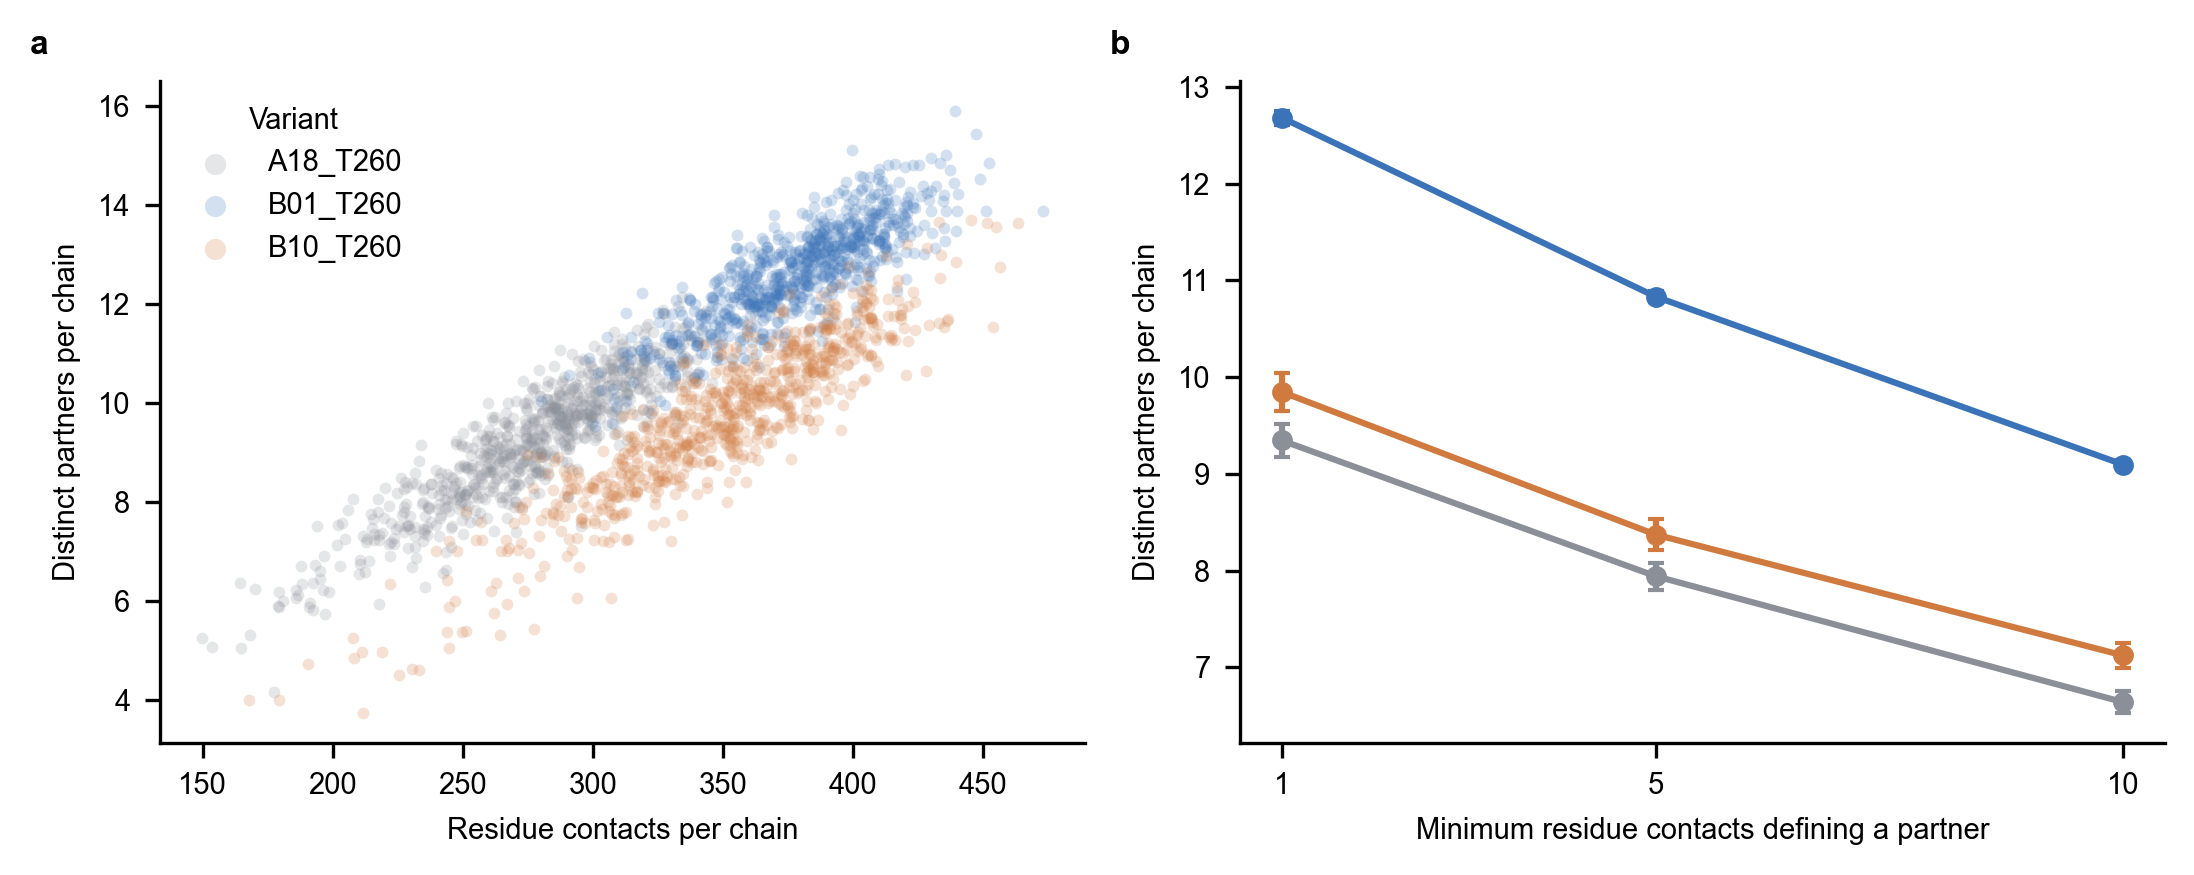

In [4]:
display(Image(filename=str(OUTPUT_DIR / "24_chain_partner_test.png")))
